Redes Neurais CNN Classificação de Imagens Food

In [ ]:
# ============================================================
# ETAPA 1 — IMPORTAR AS BIBLIOTECAS
# ============================================================

import os
import zipfile
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import load_model



In [ ]:
# ============================================================
# ETAPA 2 — FAZER UPLOAD DO ARQUIVO ZIP
# ============================================================
# Ao executar esta parte no Google Colab, clique em
# "Escolher arquivos" e selecione o arquivo .zip do dataset.

uploaded = files.upload()

# Pega automaticamente o nome do arquivo enviado.
zip_path = list(uploaded.keys())[0]

print("Arquivo enviado:", zip_path)

Saving IMAGENS.zip to IMAGENS.zip
Arquivo enviado: IMAGENS.zip


In [ ]:
# ============================================================
# ETAPA 3 — DESCOMPACTAR O DATASET
# ============================================================

pasta_extraida = "/content/dataset_original"

# Apaga a pasta antiga, caso o código seja executado novamente.
if os.path.exists(pasta_extraida):
    shutil.rmtree(pasta_extraida)

os.makedirs(pasta_extraida)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(pasta_extraida)

print("Dataset descompactado!")
print("Conteúdo inicial:", os.listdir(pasta_extraida)[:10])


Dataset descompactado!
Conteúdo inicial: ['food11']


In [ ]:
# ============================================================
# ETAPA 4 — LOCALIZAR AS IMAGENS E ORGANIZÁ-LAS POR CLASSE
# ============================================================
# O código procura arquivos de imagem e os organiza em um dicionário
# onde as chaves são os nomes das classes (subpastas) e os valores
# são listas dos caminhos completos das imagens.

imagens_por_classe = {}

# Determina o diretório raiz do dataset.
# Assume que, se há apenas uma pasta dentro de 'pasta_extraida',
# essa pasta é o diretório raiz do dataset (ex: 'food11').
conteudo_pasta_extraida = os.listdir(pasta_extraida)
# Filtra apenas diretórios, excluindo arquivos ou outras entradas.
subdirs_in_extracted = [d for d in conteudo_pasta_extraida if os.path.isdir(os.path.join(pasta_extraida, d))]

if subdirs_in_extracted:
    # Se houver subdiretórios, assume o primeiro como a raiz do dataset
    dataset_root = os.path.join(pasta_extraida, subdirs_in_extracted[0])
else:
    # Caso contrário, assume que o dataset foi extraído diretamente para 'pasta_extraida'
    dataset_root = pasta_extraida


if not os.path.isdir(dataset_root):
    print(f"Erro: O diretório do dataset não foi encontrado em {dataset_root}")
else:
    print(f"Varrendo diretório: {dataset_root}\n")
    for raiz, pastas, arquivos in os.walk(dataset_root):
        for arquivo in arquivos:
            # Verifica se é um arquivo de imagem com extensões comuns
            if arquivo.lower().endswith(('.jpg', '.jpeg', '.png', '.gif', '.bmp')):
                # O nome da classe é o nome da pasta imediatamente acima do arquivo de imagem.
                # Por exemplo, se o caminho é .../train/apple_pie/image.jpg, a classe é 'apple_pie'.
                # Se for .../apple_pie/image.jpg, a classe também é 'apple_pie'.
                class_name = os.path.basename(raiz)

                # Evita que o nome da classe seja a própria pasta raiz do dataset ou pastas de split
                forbidden_class_names = ['train', 'test', 'validation', 'val', os.path.basename(dataset_root), os.path.basename(pasta_extraida)]

                if class_name and class_name not in forbidden_class_names:
                    if class_name not in imagens_por_classe:
                        imagens_por_classe[class_name] = []
                    imagens_por_classe[class_name].append(os.path.join(raiz, arquivo))

    total_imagens = 0
    if imagens_por_classe:
        print("\nClasses e número de imagens encontradas:")
        # Ordena as classes para uma saída consistente
        for classe in sorted(imagens_por_classe.keys()):
            lista_imagens = imagens_por_classe[classe]
            print(f"- '{classe}': {len(lista_imagens)} imagens")
            total_imagens += len(lista_imagens)
    else:
        print("\nNenhuma imagem classificada encontrada. Verifique a estrutura do seu dataset.")


    print(f"\nTotal geral de imagens encontradas: {total_imagens}")

    # Exemplo de caminhos de imagem por classe
    print("\nExemplos de caminhos de imagem por classe (primeira imagem de cada classe):")
    for classe in sorted(imagens_por_classe.keys()):
        if imagens_por_classe[classe]:
            print(f"- {classe}: {imagens_por_classe[classe][0]}")

Varrendo diretório: /content/dataset_original/food11


Classes e número de imagens encontradas:
- 'apple_pie': 1000 imagens
- 'cheesecake': 1000 imagens
- 'chicken_curry': 1000 imagens
- 'french_fries': 1000 imagens
- 'fried_rice': 1000 imagens
- 'hamburger': 1000 imagens
- 'hot_dog': 1000 imagens
- 'ice_cream': 1000 imagens
- 'omelette': 1000 imagens
- 'pizza': 1000 imagens
- 'sushi': 1000 imagens

Total geral de imagens encontradas: 11000

Exemplos de caminhos de imagem por classe (primeira imagem de cada classe):
- apple_pie: /content/dataset_original/food11/test/apple_pie/185537.jpg
- cheesecake: /content/dataset_original/food11/test/cheesecake/295478.jpg
- chicken_curry: /content/dataset_original/food11/test/chicken_curry/71211.jpg
- french_fries: /content/dataset_original/food11/test/french_fries/100148.jpg
- fried_rice: /content/dataset_original/food11/test/fried_rice/180974.jpg
- hamburger: /content/dataset_original/food11/test/hamburger/184955.jpg
- hot_dog: /content/dataset_o

In [ ]:
# ============================================================
# ETAPA 5 — EMBARALHAR AS IMAGENS POR CLASSE
# ============================================================
# Usamos uma semente fixa para que o embaralhamento possa ser
# reproduzido novamente.

random.seed(123)

# Embaralha as listas de imagens para cada classe
for classe in imagens_por_classe:
    random.shuffle(imagens_por_classe[classe])

print("Imagens embaralhadas por classe.")
# Opcional: imprimir exemplos para verificar o embaralhamento (descomente se necessário)
# for classe, imagens in imagens_por_classe.items():
#     print(f"Primeiras 5 imagens de {classe} após embaralhamento: {imagens[:5]}")

Imagens embaralhadas por classe.


In [ ]:
# ============================================================
# ETAPA 6 — CRIAR TREINO, VALIDAÇÃO E TESTE
# ============================================================
# Divisão utilizada:
#
# 70% -> Treino
# 15% -> Validação
# 15% -> Teste
#
# A separação é feita individualmente para cada classe.
# Assim, mantemos as classes distribuídas entre os três conjuntos.

def dividir_dados(lista):
    total = len(lista)
    fim_treino = int(total * 0.70)
    fim_validacao = int(total * 0.85)

    treino = lista[:fim_treino]
    validacao = lista[fim_treino:fim_validacao]
    teste = lista[fim_validacao:]

    return treino, validacao, teste

# Listas para armazenar os caminhos das imagens e seus rótulos
all_train_images = []
all_train_labels = []
all_validation_images = []
all_validation_labels = []
all_test_images = []
all_test_labels = []

# Mapear nomes de classes para rótulos numéricos
class_names = sorted(imagens_por_classe.keys())
class_to_label = {name: i for i, name in enumerate(class_names)}

print("Divisão dos dados por classe...")
for class_name in class_names:
    images_in_class = imagens_por_classe[class_name]

    # Divide as imagens desta classe
    train_class, val_class, test_class = dividir_dados(images_in_class)

    # Adiciona as imagens e rótulos aos conjuntos globais
    all_train_images.extend(train_class)
    all_train_labels.extend([class_to_label[class_name]] * len(train_class))

    all_validation_images.extend(val_class)
    all_validation_labels.extend([class_to_label[class_name]] * len(val_class))

    all_test_images.extend(test_class)
    all_test_labels.extend([class_to_label[class_name]] * len(test_class))

print("\nResumo da divisão:")
print(f"Imagens de Treino: {len(all_train_images)}")
print(f"Imagens de Validação: {len(all_validation_images)}")
print(f"Imagens de Teste: {len(all_test_images)}")

print("\nExemplo de rótulos (nomes de classes para numéricos):")
for name, label_id in class_to_label.items():
    print(f"  {name}: {label_id}")

Divisão dos dados por classe...

Resumo da divisão:
Imagens de Treino: 7700
Imagens de Validação: 1650
Imagens de Teste: 1650

Exemplo de rótulos (nomes de classes para numéricos):
  apple_pie: 0
  cheesecake: 1
  chicken_curry: 2
  french_fries: 3
  fried_rice: 4
  hamburger: 5
  hot_dog: 6
  ice_cream: 7
  omelette: 8
  pizza: 9
  sushi: 10


In [ ]:
import os
import shutil

# ============================================================
# ETAPA 7 — CRIAR A ESTRUTURA DE PASTAS
# ============================================================
#
# dataset_final/
#
# ├── train/
# │   ├── apple_pie/
# │   ├── cheesecake/
# │   └── ...
# │
# ├── validation/
# │   ├── apple_pie/
# │   ├── cheesecake/
# │   └── ...
# │
# └── test/
#     ├── apple_pie/
#     ├── cheesecake/
#     └── ...

dataset_final = "/content/dataset_final"

if os.path.exists(dataset_final):
    shutil.rmtree(dataset_final)

# As classes foram identificadas na Etapa 4 e armazenadas em `class_names`
# Ex: class_names = ['apple_pie', 'cheesecake', ..., 'sushi']

pastas = []
for split_folder in ["train", "validation", "test"]:
    for class_name in class_names:
        pastas.append(os.path.join(split_folder, class_name))

print("Criando a seguinte estrutura de pastas:")
for pasta in pastas:
    full_path = os.path.join(dataset_final, pasta)
    os.makedirs(full_path, exist_ok=True)
    print(f"  {full_path}/")

print("Estrutura de pastas criada com sucesso.")

Criando a seguinte estrutura de pastas:
  /content/dataset_final/train/apple_pie/
  /content/dataset_final/train/cheesecake/
  /content/dataset_final/train/chicken_curry/
  /content/dataset_final/train/french_fries/
  /content/dataset_final/train/fried_rice/
  /content/dataset_final/train/hamburger/
  /content/dataset_final/train/hot_dog/
  /content/dataset_final/train/ice_cream/
  /content/dataset_final/train/omelette/
  /content/dataset_final/train/pizza/
  /content/dataset_final/train/sushi/
  /content/dataset_final/validation/apple_pie/
  /content/dataset_final/validation/cheesecake/
  /content/dataset_final/validation/chicken_curry/
  /content/dataset_final/validation/french_fries/
  /content/dataset_final/validation/fried_rice/
  /content/dataset_final/validation/hamburger/
  /content/dataset_final/validation/hot_dog/
  /content/dataset_final/validation/ice_cream/
  /content/dataset_final/validation/omelette/
  /content/dataset_final/validation/pizza/
  /content/dataset_final/val

In [ ]:
# ============================================================
# ETAPA 8 — COPIAR AS IMAGENS PARA AS PASTAS
# ============================================================

print("Iniciando a cópia das imagens para a nova estrutura de pastas...")

# Copiar imagens de TREINO
for i, image_path in enumerate(all_train_images):
    class_label = all_train_labels[i]
    class_name = class_names[class_label] # Obtém o nome da classe a partir do rótulo numérico
    destination_folder = os.path.join(dataset_final, "train", class_name)
    shutil.copy2(image_path, destination_folder)

print(f"Total de {len(all_train_images)} imagens de treino copiadas.")

# Copiar imagens de VALIDAÇÃO
for i, image_path in enumerate(all_validation_images):
    class_label = all_validation_labels[i]
    class_name = class_names[class_label]
    destination_folder = os.path.join(dataset_final, "validation", class_name)
    shutil.copy2(image_path, destination_folder)

print(f"Total de {len(all_validation_images)} imagens de validação copiadas.")

# Copiar imagens de TESTE
for i, image_path in enumerate(all_test_images):
    class_label = all_test_labels[i]
    class_name = class_names[class_label]
    destination_folder = os.path.join(dataset_final, "test", class_name)
    shutil.copy2(image_path, destination_folder)

print(f"Total de {len(all_test_images)} imagens de teste copiadas.")

print("\nSeparação e cópia de imagens concluída!")

Iniciando a cópia das imagens para a nova estrutura de pastas...
Total de 7700 imagens de treino copiadas.
Total de 1650 imagens de validação copiadas.
Total de 1650 imagens de teste copiadas.

Separação e cópia de imagens concluída!


In [ ]:
# ============================================================
# ETAPA 9 — CONFERIR A QUANTIDADE DE IMAGENS
# ============================================================

# As classes foram identificadas na Etapa 4 e armazenadas em `class_names`

for split_type in ["train", "validation", "test"]:
    print(f"\n--- {split_type.upper()} ---")
    total_split_images = 0
    for class_name in class_names:
        folder_path = os.path.join(dataset_final, split_type, class_name)
        num_images = len(os.listdir(folder_path))
        print(f"{class_name.capitalize()}: {num_images}")
        total_split_images += num_images
    print(f"Total de imagens em {split_type.upper()}: {total_split_images}")

print("\nConferência de imagens concluída!")


--- TRAIN ---
Apple_pie: 700
Cheesecake: 700
Chicken_curry: 700
French_fries: 700
Fried_rice: 700
Hamburger: 700
Hot_dog: 700
Ice_cream: 700
Omelette: 700
Pizza: 700
Sushi: 700
Total de imagens em TRAIN: 7700

--- VALIDATION ---
Apple_pie: 150
Cheesecake: 150
Chicken_curry: 150
French_fries: 150
Fried_rice: 150
Hamburger: 150
Hot_dog: 150
Ice_cream: 150
Omelette: 150
Pizza: 150
Sushi: 150
Total de imagens em VALIDATION: 1650

--- TEST ---
Apple_pie: 150
Cheesecake: 150
Chicken_curry: 150
French_fries: 150
Fried_rice: 150
Hamburger: 150
Hot_dog: 150
Ice_cream: 150
Omelette: 150
Pizza: 150
Sushi: 150
Total de imagens em TEST: 1650

Conferência de imagens concluída!


In [ ]:
# ============================================================
# ETAPA 10 — CARREGAR OS DATASETS COM O KERAS
# ============================================================
# Todas as imagens serão redimensionadas para 150 x 150.
# batch_size = 32 significa que o modelo trabalha com
# grupos de 32 imagens por vez.

img_size = (150, 150)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_final + "/train",
    image_size=img_size,
    batch_size=batch_size,
    shuffle=True,
    seed=123
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_final + "/validation",
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_final + "/test",
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

class_names = train_ds.class_names

print("\nClasses encontradas:", class_names)


Found 7700 files belonging to 11 classes.
Found 1650 files belonging to 11 classes.
Found 1650 files belonging to 11 classes.

Classes encontradas: ['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']


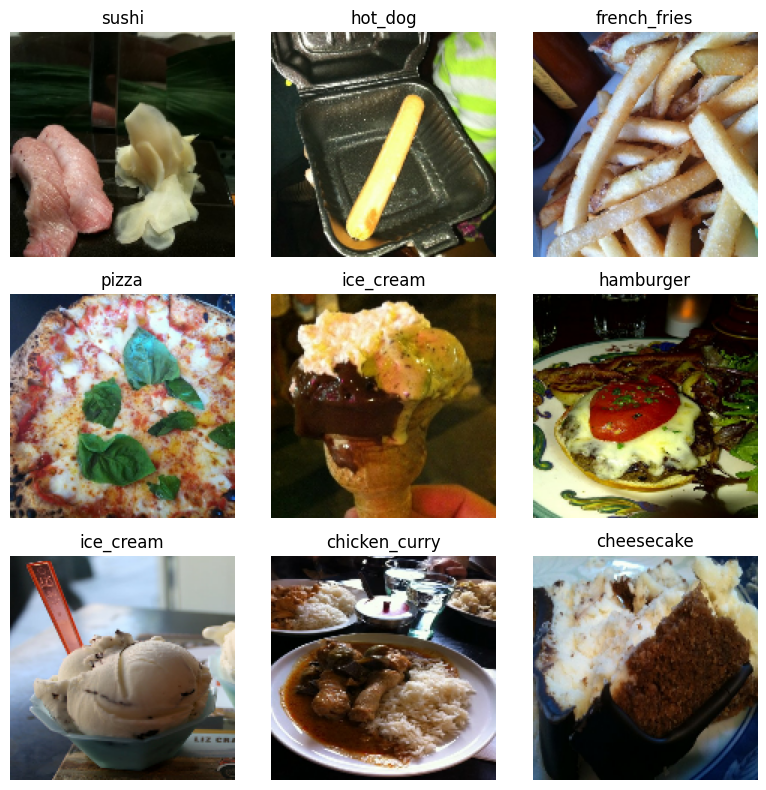

In [ ]:
# ============================================================
# ETAPA 11 — VISUALIZAR ALGUMAS IMAGENS
# ============================================================

plt.figure(figsize=(8, 8))

for imagens, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(imagens[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# ETAPA 12 — CRIAR A REDE NEURAL CONVOLUCIONAL (CNN)
# ============================================================
#
# Rescaling:
# transforma pixels de 0-255 para valores entre 0-1.
#
# Conv2D:
# procura características nas imagens.
#
# MaxPooling2D:
# reduz o tamanho das informações.
#
# Dropout:
# desliga aleatoriamente uma porcentagem dos neurônios
# para evitar o overfitting.
#
# Flatten:
# transforma os mapas de características em um vetor.
#
# Dense:
# realiza a classificação.
#
# Sigmoid:
# usada porque temos duas classes: gatos e cachorros.

model = models.Sequential([

    layers.Input(shape=(150, 150, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.3), # Adicionado Dropout

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.3), # Adicionado Dropout

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.3), # Adicionado Dropout

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3), # Adicionado Dropout antes da camada densa final

    layers.Dense(11, activation="softmax")
])

In [ ]:
# ============================================================
# ETAPA 13 — COMPILAR O MODELO - A compilação é um passo essencial antes de treinar o modelo, onde você configura como o modelo será treinado.
# ============================================================
#
# Adam:
# ajusta os pesos da rede.
#
# binary_crossentropy:
# mede o erro em uma classificação com duas classes.
#
# accuracy:
# mede a porcentagem de acertos.

model.compile(
    optimizer="adam",                 # Otimizador é o algoritimo que o modelo usa para ajustar os pesos da rede beural durante o treinamento
    loss="sparse_categorical_crossentropy",       # Função de perda mede quão bom (ou ruim) o modelo está se saindo, quanto menor o valor de perda, melhor o modelo esta prevendo os resultados
    metrics=["accuracy"]              # As métricas são usadas para monitorar o desempenho do modelo durante o treinamento e avaliação.
)

In [ ]:
# ============================================================
# ETAPA 14 — MOSTRAR A ESTRUTURA DA CNN
# ============================================================

model.summary()


# ============================================================
# ETAPA 15 — CRIAR O CHECKPOINT
# ============================================================
# O checkpoint salva o modelo que apresentar o MENOR
# erro de validação (val_loss).

checkpoint = ModelCheckpoint(
    "/content/melhor_modelo.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,771 (18.42 MB)

 Trainable params: 4,829,771 (18.42 MB)

 Non-trainable params: 0 (0.00 B)


model.summary() (Etapa 14 — Mostrar a Estrutura da CNN):

Este comando exibe um resumo detalhado da arquitetura da sua Rede Neural Convolucional (model).
Ele mostra cada camada na ordem em que foram definidas, incluindo o tipo da camada (ex: Conv2D, MaxPooling2D, Dense), a forma de saída de cada camada (Output Shape), e o número de parâmetros treináveis (Param #) em cada camada.
A forma de saída ( Output Shape) indica as dimensões dos dados após passarem por cada camada. Por exemplo, (None, 150, 150, 32)significa que para um lote de imagens de qualquer tamanho ( None), as imagens têm 150x150 pixels e 32 canais (filtros).
O número de parâmetros (Param #) indica quantos pesos e vieses a rede precisa aprender naquela camada. A soma total de Param # lhe dará o número total de parâmetros treináveis do seu modelo.
É uma ferramenta muito útil para verificar se a arquitetura do modelo está como você esperava, especialmente a compatibilidade das formas de entrada/saída entre as camadas.
checkpoint = ModelCheckpoint(...) (Etapa 15 — Criar o Checkpoint):

Um ModelCheckpoint é um callback (uma função que é chamada em certos momentos durante o treinamento) do Keras. Ele é usado para salvar o modelo automaticamente durante o treinamento.
"/content/melhor_modelo.keras": Este é o caminho e nome do arquivo onde o modelo será salvo. O modelo será salvo no formato Keras nativo.
monitor="val_loss": Este parâmetro indica qual métrica o checkpoint deve "monitorar". Neste caso, ele monitora a perda de validação (val_loss). O objetivo é que esta métrica seja a menor possível.
save_best_only=True: Este é um parâmetro muito importante. Ele garante que o checkpoint só salvará o modelo se a métrica monitorada (val_loss) for melhor do que o melhor valor anterior. Isso significa que, ao final do treinamento, você terá salvo apenas a versão do modelo que obteve o menor erro no conjunto de validação.
mode="min": Define a direção da "melhoria" para a métrica monitorada. Como val_loss deve ser minimizada, mode="min" é o correto. Se estivesse monitorando accuracy, usaríamos mode="max".
verbose=1: Faz com que o checkpointimprima mensagens informativas durante o treinamento sempre que um modelo for salvo.
Reforçando a Observação Importante:

Como mencionei anteriormente, seu dataset possui 11 classes de comida, mas o modelo que você definiu (Jk210uvJBXQV) e compilou (Ohr9vF8GCWQ5) ainda está configurado para classificação binária (duas classes). Isso afeta diretamente a interpretação do model.summary() (que mostrará a camada final com 1 saída) e o val_loss monitorado pelo checkpoint (que será binary_crossentropy).

Para que o modelo possa classificar corretamente as 11 classes, é essencial fazer as seguintes modificações:

Na célula Jk210uvJBXQV (criação do modelo):

A última camada Dense deve ter o número de neurônios igual ao número de classes (11) e usar a função de ativação softmax.
Mude: layers.Dense(1, activation="sigmoid")
Para: layers.Dense(len(class_names), activation="softmax")
Na célula Ohr9vF8GCWQ5 (compilação do modelo):

A função de perda deve ser sparse_categorical_crossentropy.
Mude: loss="binary_crossentropy"
Para: loss="sparse_categorical_crossentropy"

In [ ]:
# ============================================================
# ETAPA 16 — TREINAR A CNN
# ============================================================
# Uma época significa uma passagem completa pelos dados
# de treinamento.
#
# O conjunto de teste NÃO é utilizado nesta etapa.

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[checkpoint]
)


Epoch 1/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.1012 - loss: 2.4817
Epoch 1: val_loss improved from None to 2.29020, saving model to /content/melhor_modelo.keras

Epoch 1: finished saving model to /content/melhor_modelo.keras
241/241 ━━━━━━━━━━━━━━━━━━━━ 28s 83ms/step - accuracy: 0.1199 - loss: 2.3815 - val_accuracy: 0.1697 - val_loss: 2.2902
Epoch 2/10
240/241 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.1643 - loss: 2.2839
Epoch 2: val_loss improved from 2.29020 to 2.19048, saving model to /content/melhor_modelo.keras

Epoch 2: finished saving model to /content/melhor_modelo.keras
241/241 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - accuracy: 0.1905 - loss: 2.2441 - val_accuracy: 0.2024 - val_loss: 2.1905
Epoch 3/10
240/241 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.2245 - loss: 2.1821
Epoch 3: val_loss improved from 2.19048 to 2.11755, saving model to /content/melhor_modelo.keras

Epoch 3: finished saving model to /content/melhor_modelo.keras
241/241 ━━━━━━━━━━━━━

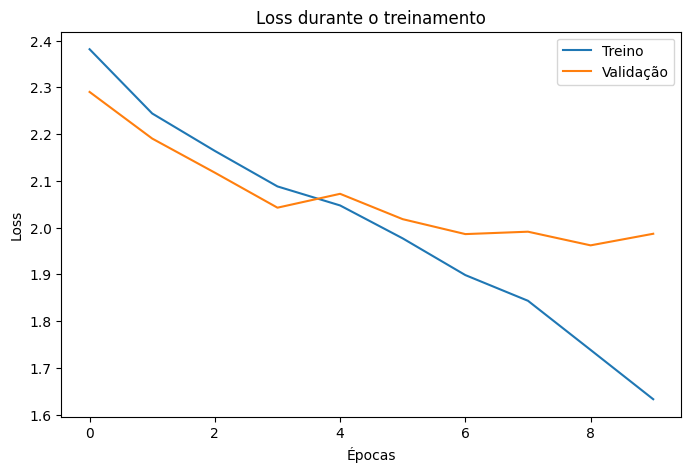

In [ ]:
# ============================================================
# ETAPA 17 — GRÁFICO DO LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Treino")
plt.plot(history.history["val_loss"], label="Validação")

plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.title("Loss durante o treinamento")
plt.legend()

plt.show()


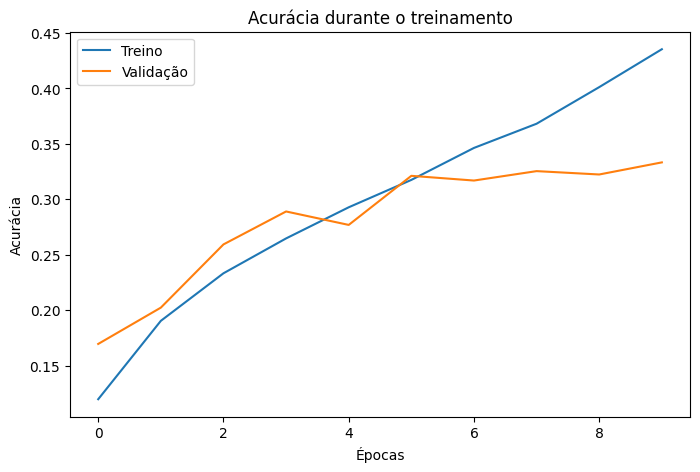

In [ ]:
# ============================================================
# ETAPA 18 — GRÁFICO DA ACURÁCIA
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Treino")
plt.plot(history.history["val_accuracy"], label="Validação")

plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.title("Acurácia durante o treinamento")
plt.legend()

plt.show()

In [ ]:
# ============================================================
# ETAPA 19 — IDENTIFICAR A MELHOR ÉPOCA
# ============================================================

melhor_epoca = np.argmin(history.history["val_loss"]) + 1
melhor_val_loss = np.min(history.history["val_loss"])

print("Melhor época:", melhor_epoca)
print("Menor val_loss:", melhor_val_loss)

Melhor época: 9
Menor val_loss: 1.962080717086792


In [ ]:
# ============================================================
# ETAPA 20 — CARREGAR O MELHOR MODELO
# ============================================================

melhor_modelo = load_model("/content/melhor_modelo.keras")

print("Melhor modelo carregado!")

Melhor modelo carregado!


In [ ]:
# ============================================================
# ETAPA 21 — AVALIAÇÃO FINAL COM O CONJUNTO DE TESTE
# ============================================================
# Somente agora usamos o conjunto de teste.
#
# Essas imagens não foram utilizadas para treinar o modelo
# nem para escolher a melhor época.

test_loss, test_accuracy = melhor_modelo.evaluate(test_ds)

print("\nRESULTADO FINAL")
print("Loss no teste:", test_loss)
print("Acurácia no teste:", test_accuracy)
print("Acurácia no teste (%):", test_accuracy * 100)

52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.3206 - loss: 1.9905

RESULTADO FINAL
Loss no teste: 1.9905250072479248
Acurácia no teste: 0.3206060528755188
Acurácia no teste (%): 32.06060528755188


In [ ]:
# ============================================================
# ETAPA 22 — FAZER PREVISÕES NO CONJUNTO DE TESTE
# ============================================================
# Em problemas multi-classe, `model.predict` retorna a probabilidade
# para cada classe. A classe prevista é aquela com a maior probabilidade.

imagens_lista = []
reais_lista = []
previstos_lista = []
probabilidades_lista = [] # Para armazenar as probabilidades da classe prevista

for imagens, labels in test_ds:
    # melhor_modelo.predict retorna um array (batch_size, num_classes)
    probabilidades_por_classe = melhor_modelo.predict(imagens, verbose=0)

    # Para cada imagem, a previsão é o índice da classe com a maior probabilidade
    previsoes = np.argmax(probabilidades_por_classe, axis=1)

    imagens_lista.extend(imagens.numpy())
    reais_lista.extend(labels.numpy())
    previstos_lista.extend(previsoes)

    # Armazenar a probabilidade da classe que foi prevista
    prob_predita_por_imagem = [probabilidades_por_classe[i, previsoes[i]] for i in range(len(previsoes))]
    probabilidades_lista.extend(prob_predita_por_imagem)

print("Previsões realizadas!")

Previsões realizadas!


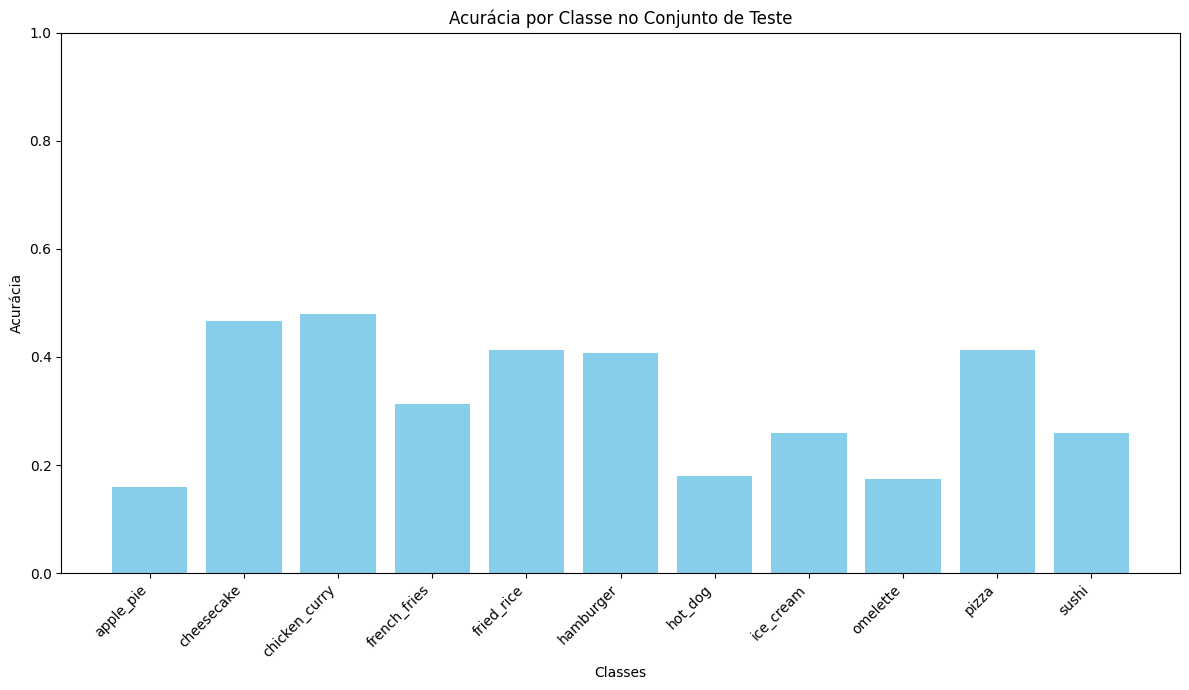

<Figure size 1000x1000 with 0 Axes>

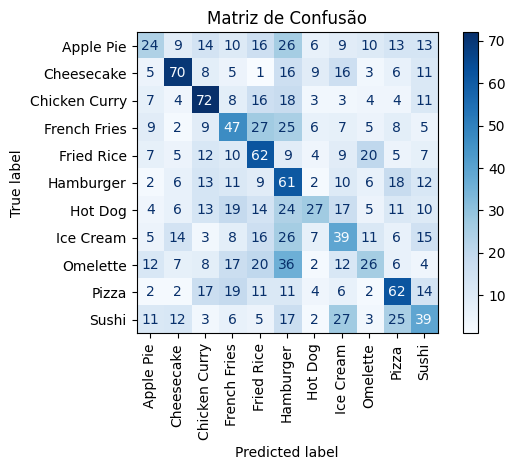

Gráficos de resultados de teste gerados!


In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ============================================================
# ETAPA 26 — GRÁFICO DE ACURÁCIA POR CLASSE NO TESTE
# ============================================================

# Converter as listas para numpy arrays para facilitar a indexação
reais_array = np.array(reais_lista)
previstos_array = np.array(previstos_lista)

# Calcular a acurácia por classe
acuracia_por_classe = {}
for i, class_name in enumerate(class_names):
    # Filtra os rótulos verdadeiros e previstos para a classe atual
    indices_da_classe = np.where(reais_array == i)
    reais_classe = reais_array[indices_da_classe]
    previstos_classe = previstos_array[indices_da_classe]

    if len(reais_classe) > 0:
        acertos_classe = np.sum(reais_classe == previstos_classe)
        acuracia = acertos_classe / len(reais_classe)
        acuracia_por_classe[class_name] = acuracia
    else:
        acuracia_por_classe[class_name] = 0.0 # Sem imagens para esta classe no teste

# Criar o gráfico de barras
plt.figure(figsize=(12, 7))
plt.bar(acuracia_por_classe.keys(), acuracia_por_classe.values(), color='skyblue')
plt.xlabel("Classes")
plt.ylabel("Acurácia")
plt.title("Acurácia por Classe no Conjunto de Teste")
plt.xticks(rotation=45, ha='right') # Rotaciona os rótulos para melhor visualização
plt.ylim(0, 1) # A acurácia varia de 0 a 1
plt.tight_layout()
plt.show()


# ============================================================
# ETAPA 27 — MATRIZ DE CONFUSÃO (Opcional, mas muito útil)
# ============================================================

# Gera a matriz de confusão
cm = confusion_matrix(reais_lista, previstos_lista, labels=range(len(class_names)))
display_labels = [name.replace('_', ' ').title() for name in class_names] # Nomes formatados

plt.figure(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title("Matriz de Confusão")
plt.tight_layout()
plt.show()

print("Gráficos de resultados de teste gerados!")

In [ ]:
# ============================================================
# ETAPA 23 — LOCALIZAR OS ACERTOS E OS ERROS
# ============================================================

acertos = []
erros = []

for i in range(len(reais_lista)):

    if reais_lista[i] == previstos_lista[i]:
        acertos.append(i)

    else:
        erros.append(i)

print("Quantidade de acertos:", len(acertos))
print("Quantidade de erros:", len(erros))

Quantidade de acertos: 529
Quantidade de erros: 1121


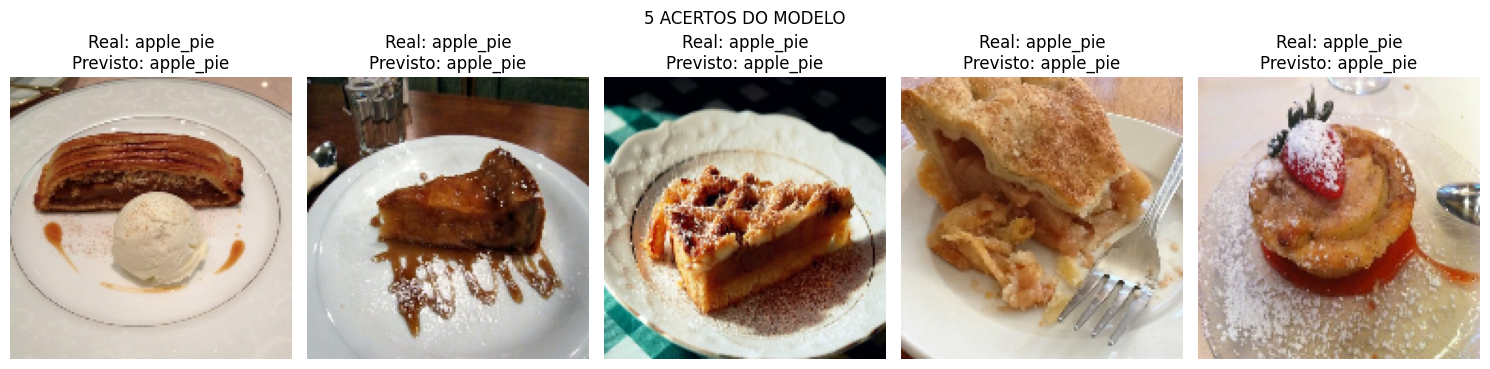

In [ ]:
# ============================================================
# ETAPA 24 — MOSTRAR 5 ACERTOS
# ============================================================

plt.figure(figsize=(15, 4))

for posicao, i in enumerate(acertos[:5]):

    plt.subplot(1, 5, posicao + 1)

    plt.imshow(imagens_lista[i].astype("uint8"))

    real = class_names[int(reais_lista[i])]
    previsto = class_names[int(previstos_lista[i])]

    plt.title(
        f"Real: {real}\n"
        f"Previsto: {previsto}"
    )

    plt.axis("off")

plt.suptitle("5 ACERTOS DO MODELO")
plt.tight_layout()
plt.show()


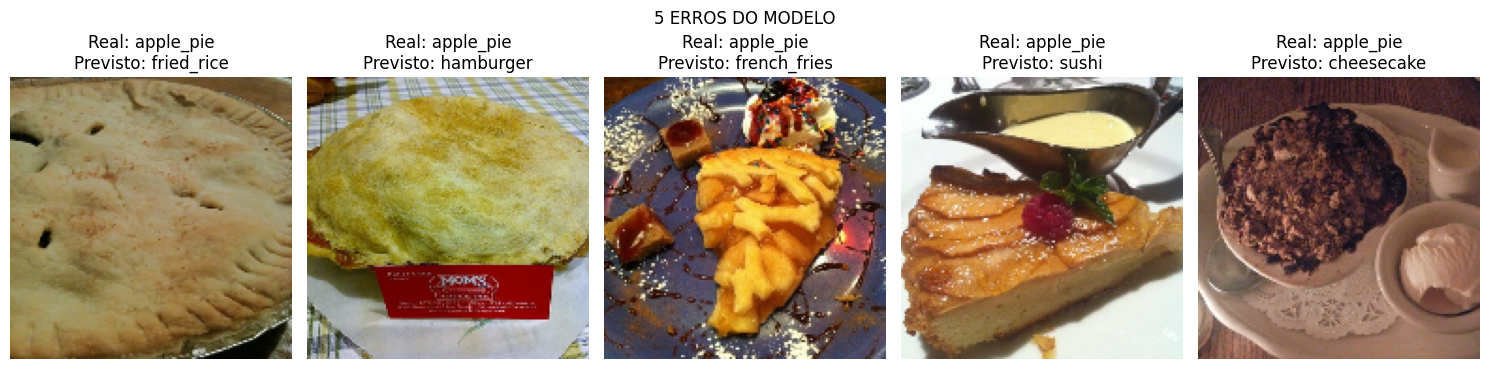

In [ ]:
# ============================================================
# ETAPA 25 — MOSTRAR 5 ERROS
# ============================================================

if len(erros) > 0:

    quantidade = min(5, len(erros))

    plt.figure(figsize=(15, 4))

    for posicao, i in enumerate(erros[:quantidade]):

        plt.subplot(1, quantidade, posicao + 1)

        plt.imshow(imagens_lista[i].astype("uint8"))

        real = class_names[int(reais_lista[i])]
        previsto = class_names[int(previstos_lista[i])]

        plt.title(
            f"Real: {real}\n"
            f"Previsto: {previsto}"
        )

        plt.axis("off")

    plt.suptitle("5 ERROS DO MODELO")
    plt.tight_layout()
    plt.show()

else:
    print("O modelo não apresentou erros no conjunto de teste.")


In [ ]:
# ============================================================
# FIM DA PIPELINE
# ============================================================
#
# RESUMO:
#
# 1. Upload do ZIP
# 2. Descompactação
# 3. Identificação de gatos e cachorros
# 4. Separação:
#       70% treino
#       15% validação
#       15% teste
# 5. Carregamento das imagens
# 6. Criação da CNN
# 7. Treinamento
# 8. Checkpoint pelo menor val_loss
# 9. Gráficos de loss e acurácia
# 10. Carregamento do melhor modelo
# 11. Avaliação no conjunto de teste
# 12. Exibição de 5 acertos
# 13. Exibição de 5 erros
# ============================================================
